In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cpu


In [2]:
repo_root = Path.cwd()
if repo_root.name in {'vanilla-code', 'your-sollution', 'your_solution'}:
    repo_root = repo_root.parent

def dataset_path(task_name: str, filename: str) -> str:
    local_path = repo_root / 'dataset' / task_name / filename
    if local_path.exists():
        return str(local_path)
    return (
        'https://github.com/AI-is-out-there/'
        'check-your-biomed-datascience-skills-review/raw/refs/heads/dev/'
        f'dataset/{task_name}/{filename}'
    )

df = pd.read_csv(dataset_path('task2_1', 'train.csv'))
test_features = pd.read_csv(dataset_path('task2_1', 'test_features.csv'))

feature_cols = [c for c in df.columns if c.startswith('t_')]
X = df[feature_cols].to_numpy(dtype=np.float32)
y = df['prediction'].to_numpy(dtype=np.int64)

label_names = ['N (Normal)', 'R-on-T PVC', 'PVC', 'SP or EB', 'UB']
print('train:', df.shape, '| test:', test_features.shape, '| длина сигнала:', len(feature_cols))
print('пропуски:', int(df[feature_cols].isna().sum().sum()), int(test_features[feature_cols].isna().sum().sum()))

train: (4000, 142) | test: (1000, 141) | длина сигнала: 140
пропуски: 0 0


,класс,количество,доля
0,N (Normal),2335,0.58375
1,R-on-T PVC,1414,0.35350
2,PVC,77,0.01925
3,SP or EB,155,0.03875
4,UB,19,0.00475


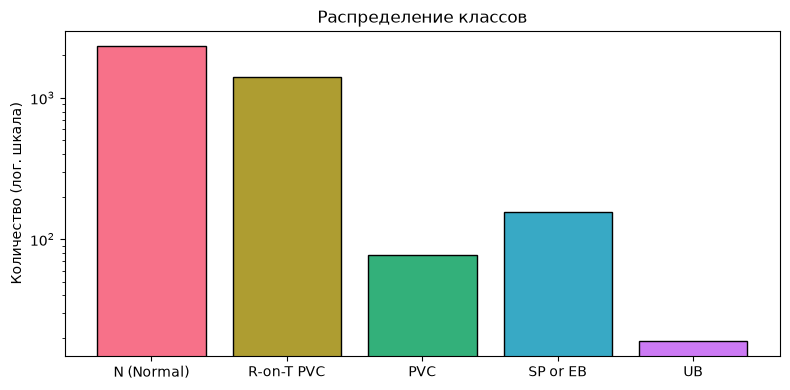

In [3]:
counts = pd.Series(y).value_counts().sort_index()
balance = pd.DataFrame({'класс': label_names, 'количество': counts.values, 'доля': (counts / counts.sum()).values})
display(balance)

plt.figure(figsize=(8, 4))
plt.bar(label_names, counts.values, color=sns.color_palette('husl', 5), edgecolor='black')
plt.yscale('log')
plt.ylabel('Количество (лог. шкала)')
plt.title('Распределение классов')
plt.tight_layout()
plt.show()

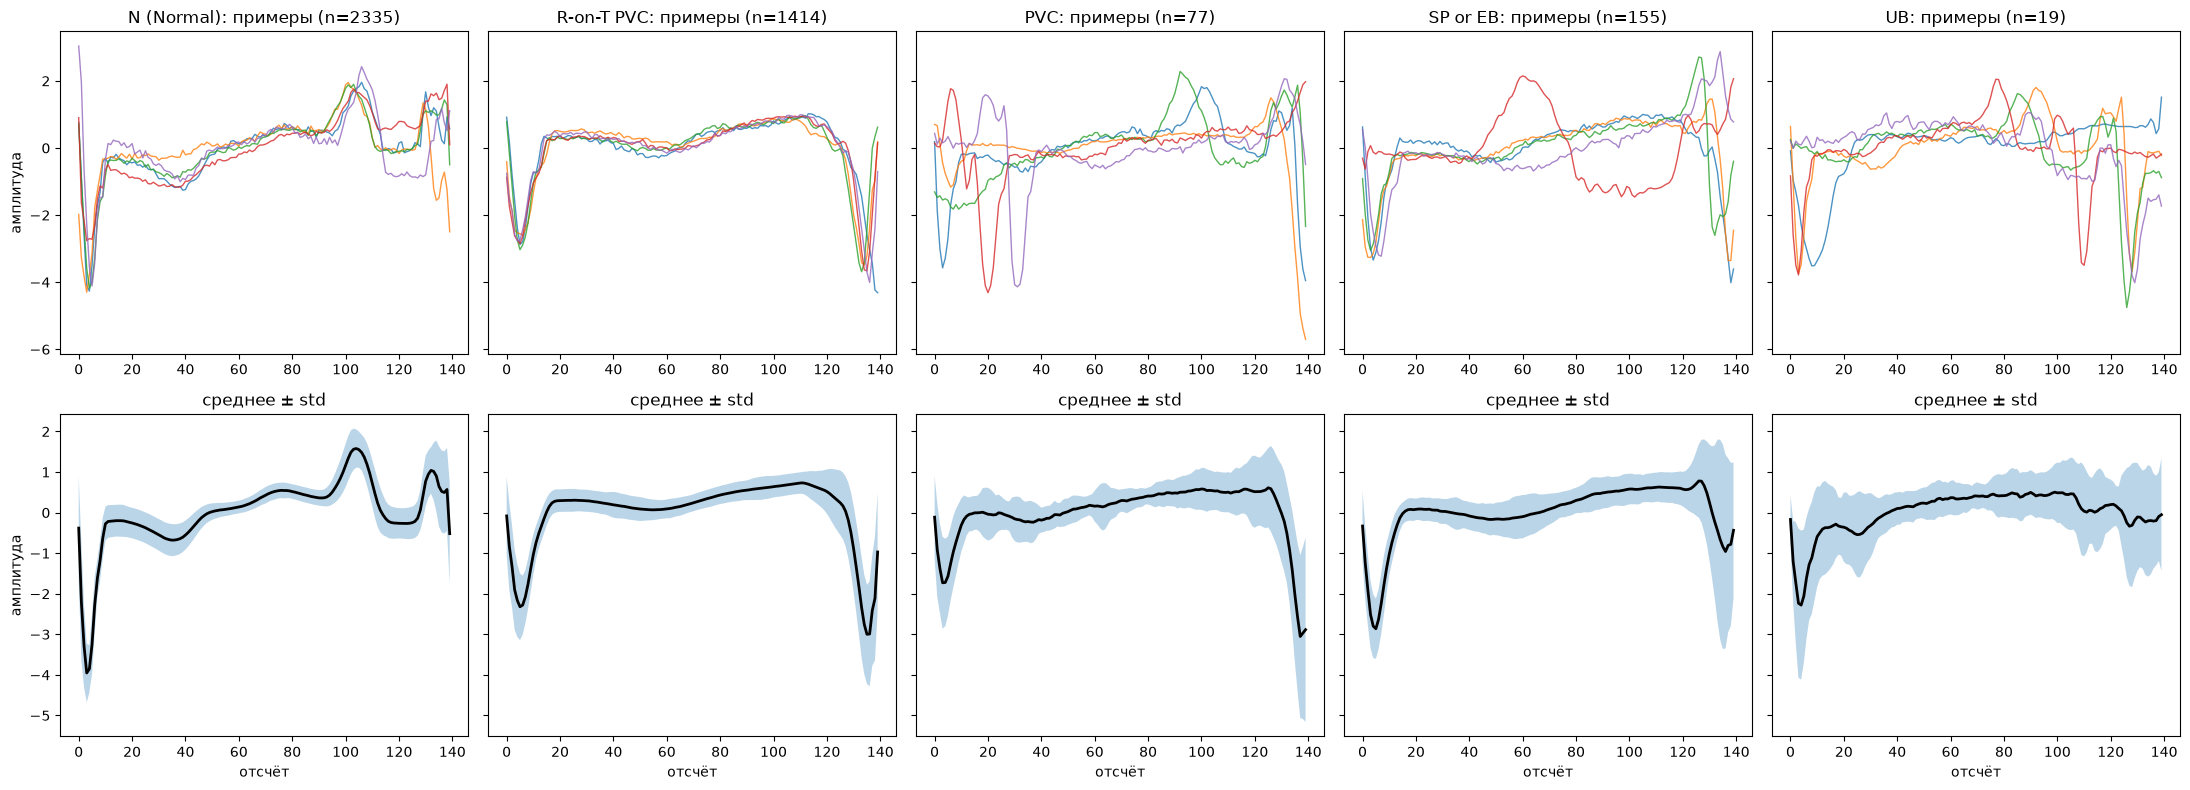

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8), sharey='row')
rng = np.random.default_rng(SEED)
for c in range(5):
    idx = np.where(y == c)[0]
    for i in rng.choice(idx, size=min(5, len(idx)), replace=False):
        axes[0, c].plot(X[i], lw=1, alpha=0.8)
    axes[0, c].set_title(f'{label_names[c]}: примеры (n={len(idx)})')
    mean, std = X[idx].mean(0), X[idx].std(0)
    axes[1, c].plot(mean, color='black', lw=2)
    axes[1, c].fill_between(range(len(mean)), mean - std, mean + std, alpha=0.3)
    axes[1, c].set_title('среднее ± std')
    axes[1, c].set_xlabel('отсчёт')
axes[0, 0].set_ylabel('амплитуда')
axes[1, 0].set_ylabel('амплитуда')
plt.tight_layout()
plt.show()

In [5]:
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.1765, stratify=y_trainval, random_state=SEED)

scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (scaler.transform(a) for a in (X_train, X_val, X_test))

split_counts = pd.DataFrame({name: np.bincount(t, minlength=5) for name, t in
                             [('train', y_train), ('val', y_val), ('test', y_test)]}, index=label_names)
display(split_counts)

def to_loader(features, targets, batch_size=64, shuffle=False):
    g = torch.Generator().manual_seed(SEED)
    ds = TensorDataset(torch.tensor(features[:, None, :], dtype=torch.float32), torch.tensor(targets, dtype=torch.long))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g)

train_loader = to_loader(X_train_s, y_train, shuffle=True)
val_loader = to_loader(X_val_s, y_val)
test_loader = to_loader(X_test_s, y_test)

,train,val,test
N (Normal),1634,351,350
R-on-T PVC,990,212,212
PVC,53,12,12
SP or EB,109,23,23
UB,13,3,3


In [6]:
class ECGClassifier(nn.Module):
    def __init__(self, n_classes=5):
        super().__init__()
        def block(c_in, c_out, k):
            return nn.Sequential(nn.Conv1d(c_in, c_out, k, padding=k // 2), nn.BatchNorm1d(c_out), nn.ReLU())
        self.features = nn.Sequential(
            block(1, 32, 7), nn.MaxPool1d(2),
            block(32, 64, 5), nn.MaxPool1d(2),
            block(64, 128, 3), nn.AdaptiveAvgPool1d(1),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

class_counts = np.bincount(y_train, minlength=5)
class_weights = np.sqrt(len(y_train) / (5 * class_counts))
class_weights = class_weights / class_weights.mean()
print('веса классов:', {n: round(float(w), 2) for n, w in zip(label_names, class_weights)})

model = ECGClassifier().to(device)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)
print('параметров:', sum(p.numel() for p in model.parameters()))

веса классов: {'N (Normal)': 0.22, 'R-on-T PVC': 0.28, 'PVC': 1.21, 'SP or EB': 0.84, 'UB': 2.45}
параметров: 44293


In [7]:
def run_epoch(loader, train_mode=False):
    model.train(train_mode)
    total_loss, preds_all, targets_all = 0.0, [], []
    with torch.set_grad_enabled(train_mode):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train_mode:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(xb)
            preds_all.extend(logits.argmax(1).cpu().numpy())
            targets_all.extend(yb.cpu().numpy())
    return total_loss / len(loader.dataset), accuracy_score(targets_all, preds_all), f1_score(targets_all, preds_all, average='macro')

history = {k: [] for k in ['train_loss', 'val_loss', 'train_f1', 'val_f1']}
best_val_f1, best_epoch, best_state, wait, patience = -1.0, 0, None, 0, 10

for epoch in range(1, 61):
    tr_loss, _, tr_f1 = run_epoch(train_loader, train_mode=True)
    va_loss, va_acc, va_f1 = run_epoch(val_loader)
    scheduler.step(va_f1)
    for k, v in zip(history, [tr_loss, va_loss, tr_f1, va_f1]):
        history[k].append(v)
    if epoch % 5 == 0 or va_f1 > best_val_f1:
        print(f'epoch={epoch:02d} train_loss={tr_loss:.4f} val_loss={va_loss:.4f} train_f1={tr_f1:.4f} val_f1={va_f1:.4f} val_acc={va_acc:.4f}')
    if va_f1 > best_val_f1:
        best_val_f1, best_epoch, wait = va_f1, epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
        if wait >= patience:
            print(f'Ранняя остановка на эпохе {epoch}')
            break

model.load_state_dict(best_state)
print(f'Лучшая эпоха: {best_epoch}, macro F1 на валидации: {best_val_f1:.4f}')

epoch=01 train_loss=1.1239 val_loss=0.9177 train_f1=0.3184 val_f1=0.3641 val_acc=0.8469


epoch=02 train_loss=0.7024 val_loss=0.6763 train_f1=0.4184 val_f1=0.4302 val_acc=0.8852


epoch=03 train_loss=0.5959 val_loss=0.6017 train_f1=0.4461 val_f1=0.5267 val_acc=0.9135


epoch=05 train_loss=0.4930 val_loss=0.5094 train_f1=0.5675 val_f1=0.5629 val_acc=0.9218


epoch=09 train_loss=0.4296 val_loss=0.4717 train_f1=0.6144 val_f1=0.6175 val_acc=0.9251


...

epoch=31 train_loss=0.2175 val_loss=0.4261 train_f1=0.7709 val_f1=0.6545 val_acc=0.9418


epoch=35 train_loss=0.1979 val_loss=0.5044 train_f1=0.7958 val_f1=0.6605 val_acc=0.9418


epoch=40 train_loss=0.1697 val_loss=0.4550 train_f1=0.8498 val_f1=0.6679 val_acc=0.9434


epoch=45 train_loss=0.1564 val_loss=0.5884 train_f1=0.8411 val_f1=0.6256 val_acc=0.9384


epoch=50 train_loss=0.1504 val_loss=0.5442 train_f1=0.8473 val_f1=0.6176 val_acc=0.9384
Ранняя остановка на эпохе 50
Лучшая эпоха: 40, macro F1 на валидации: 0.6679


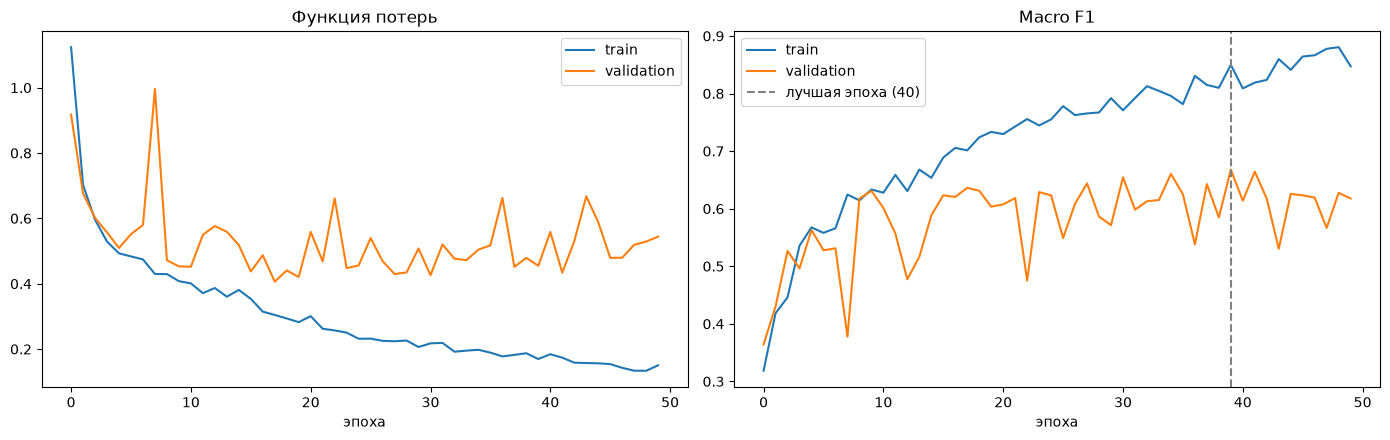

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['val_loss'], label='validation')
axes[0].set_title('Функция потерь')
axes[0].set_xlabel('эпоха')
axes[1].plot(history['train_f1'], label='train')
axes[1].plot(history['val_f1'], label='validation')
axes[1].axvline(best_epoch - 1, ls='--', color='gray', label=f'лучшая эпоха ({best_epoch})')
axes[1].set_title('Macro F1')
axes[1].set_xlabel('эпоха')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [9]:
model.eval()
with torch.no_grad():
    test_logits = model(torch.tensor(X_test_s[:, None, :], dtype=torch.float32, device=device))
test_preds = test_logits.argmax(1).cpu().numpy()

print(f'Test accuracy: {accuracy_score(y_test, test_preds):.4f}')
print(f'Test macro F1: {f1_score(y_test, test_preds, average="macro"):.4f}')
print(classification_report(y_test, test_preds, target_names=label_names, digits=3, zero_division=0))

Test accuracy: 0.9217
Test macro F1: 0.5675
              precision    recall  f1-score   support

  N (Normal)      0.980     0.977     0.979       350
  R-on-T PVC      0.946     0.915     0.930       212
         PVC      0.400     0.667     0.500        12
    SP or EB      0.474     0.391     0.429        23
          UB      0.000     0.000     0.000         3

    accuracy                          0.922       600
   macro avg      0.560     0.590     0.568       600
weighted avg      0.932     0.922     0.926       600



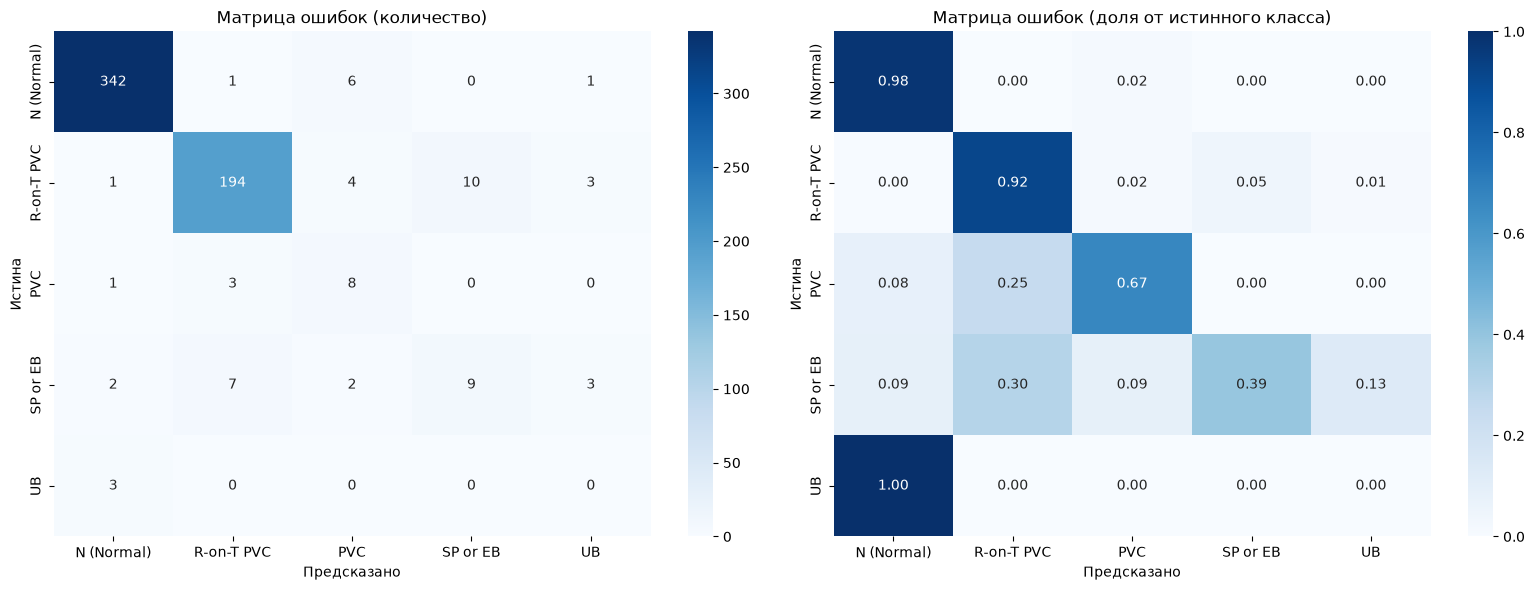

,истина,предсказано,число
5,R-on-T PVC,SP or EB,10
10,SP or EB,R-on-T PVC,7
1,N (Normal),PVC,6
4,R-on-T PVC,PVC,4
6,R-on-T PVC,UB,3
12,SP or EB,UB,3
13,UB,N (Normal),3
8,PVC,R-on-T PVC,3
11,SP or EB,PVC,2
9,SP or EB,N (Normal),2


In [10]:
cm = confusion_matrix(y_test, test_preds, labels=range(5))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names, ax=axes[0])
axes[0].set_title('Матрица ошибок (количество)')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=label_names, yticklabels=label_names, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title('Матрица ошибок (доля от истинного класса)')
for ax in axes:
    ax.set_xlabel('Предсказано')
    ax.set_ylabel('Истина')
plt.tight_layout()
plt.show()

errors = pd.DataFrame([(label_names[i], label_names[j], cm[i, j]) for i in range(5) for j in range(5) if i != j and cm[i, j] > 0],
                      columns=['истина', 'предсказано', 'число']).sort_values('число', ascending=False)
display(errors)

In [11]:
X_submission = scaler.transform(test_features[feature_cols].to_numpy(dtype=np.float32))
with torch.no_grad():
    submission_preds = model(torch.tensor(X_submission[:, None, :], dtype=torch.float32, device=device)).argmax(1).cpu().numpy()

submission = pd.DataFrame({'heartbeat_id': test_features['heartbeat_id'], 'prediction': submission_preds.astype(int)})
assert len(submission) == len(test_features)
assert submission['heartbeat_id'].equals(test_features['heartbeat_id'])
assert submission['prediction'].between(0, 4).all() and submission['prediction'].notna().all()

output_path = repo_root / 'outputs' / 'task2_1_predictions.csv'
output_path.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(output_path, index=False)
print('Сохранено:', output_path.relative_to(repo_root).as_posix())
print(submission['prediction'].map(dict(enumerate(label_names))).value_counts().to_string())

Сохранено: outputs/task2_1_predictions.csv
prediction
N (Normal)    586
R-on-T PVC    352
SP or EB       32
PVC            22
UB              8


Отчёт

Данные поделены на обучение, валидацию и тест в пропорции 70/15/15 с сохранением долей классов.

Модель - небольшая свёрточная сеть из трёх слоёв. Обучение останавливается, когда macro F1 на валидации перестаёт расти.

Классы очень неравные: обычных сокращений и R-on-T PVC 94%, а UB всего 19 штук. Поэтому ошибки на редких классах весят больше. Веса взяты как корень из обратной частоты, без корня обучение слишком скачет.

На тесте точность 0.92, macro F1 0.57. Обычные сокращения и R-on-T PVC распознаются хорошо (F1 0.98 и 0.93), PVC и SP/EB хуже (0.50 и 0.43), а UB не распознаётся совсем: в тесте их три, и все приняты за норму.

Чаще всего путаются R-on-T PVC и SP/EB, по форме они почти одинаковые. PVC сильно отличаются друг от друга, а UB слишком мало, чтобы модель их выучила. После 20 эпох сеть начинает переобучаться.